# Machine Learning for Rare-Object Discovery in Radio Surveys: A Similarity-Search Approach to Unusual Radio-Source Morphologies

**A proof-of-concept study on classical radio galaxy morphology data**

**Author:** Talha Ishtiaque
**Affiliation:** *(add your institutional affiliation here once confirmed, e.g. prospective MSc candidate, University of South Africa, Department of Mathematical Sciences — Astronomy)*
**Contact:** talha.sdk@gmail.com

---

## Abstract

Modern radio-continuum surveys such as the LOFAR Two-metre Sky Survey (LoTSS)
and the ASKAP Evolutionary Map of the Universe (EMU) contain source catalogues
numbering in the millions, with the forthcoming Square Kilometre Array (SKA)
expected to increase this by a further order of magnitude. Within such
catalogues, scientifically valuable but rare morphological classes — such as
bent-tailed radio galaxies, which trace the dynamics of the intracluster
medium in galaxy clusters — occur too infrequently, and with too much
morphological variability, to be efficiently located through visual
inspection or through classifiers restricted to a fixed label set.

In this notebook we present a proof-of-concept similarity-search pipeline for
rare radio-source discovery. We extract embeddings from radio galaxy cutouts
using DINOv2, a general-purpose self-supervised vision transformer that
requires no radio-specific fine-tuning, index them for fast approximate
nearest-neighbour retrieval using FAISS, and evaluate the approach with a
controlled *needle-in-a-haystack* recovery experiment: examples of a rare
class (bent-tailed radio galaxies) are held out and mixed into a much larger,
nominally unlabelled pool of common-class sources (FRI/FRII radio galaxies),
and we measure how reliably a similarity search recovers them.

This notebook uses the classical Aniyan & Thorat (2017) radio galaxy dataset
as a fast, freely available, GPU-friendly testbed for the method, ahead of
scaling the same pipeline to full survey data (LoTSS-DR2, ASKAP EMU) as part
of ongoing MSc research. We report precision@k and recall@k, averaged over
multiple independent queries rather than a single anecdotal example, and
visualise the embedding space to give qualitative insight alongside the
quantitative metrics.

**Keywords:** radio astronomy, self-supervised learning, DINOv2, similarity
search, anomaly detection, bent-tailed radio galaxies, FRI/FRII
classification


## 1. Introduction and motivation

### 1.1 The discovery problem at survey scale

Radio-continuum surveys have grown from catalogues of a few thousand sources
to tens of millions. The LOFAR Two-metre Sky Survey Data Release 2 (LoTSS-DR2;
Shimwell et al.) and the ASKAP EMU pilot survey already contain source counts
that make exhaustive visual inspection infeasible, and the SKA is expected to
push this further still. Supervised classifiers trained on a fixed set of
morphological classes (e.g. Fanaroff–Riley Class I and II, or "FRI"/"FRII")
are effective for sources resembling their training distribution, but by
construction cannot flag examples of classes they were never shown — which is
precisely the situation for genuinely rare or previously uncatalogued
morphologies.

### 1.2 Why bent-tailed radio galaxies as a test case

Bent-tailed (and wide-angle-tail) radio galaxies are a scientifically
motivated rare-class target: their characteristic bent radio lobes result
from the motion of the host galaxy relative to the surrounding intracluster
medium, making them useful tracers of galaxy-cluster dynamics and merger
activity. They are also comparatively rare relative to the general radio
galaxy population, and morphologically distinct enough to make a tractable
first test case for a discovery pipeline, before attempting genuinely novel,
previously uncatalogued morphological classes (e.g. odd radio circles) at
full survey scale.

### 1.3 Why a similarity-search framing, rather than classification

Framing discovery as *similarity search* rather than *classification* has a
specific advantage: a human expert can query the system with one or a
handful of known examples of a rare class and retrieve morphologically
similar candidates from an otherwise unlabelled sample, without requiring a
large labelled training set for that class. This is closer to how discovery
actually happens in practice — an astronomer notices one unusual object and
wants to know "are there others like this?" — and it is the framing we adopt
and evaluate here.

### 1.4 Scope of this notebook

This notebook is explicitly a **proof-of-concept on a small, classical
dataset**, not a survey-scale result. It is designed to:

1. Validate the similarity-search methodology end-to-end on real (if modest)
   radio galaxy data, using free Kaggle GPU compute;
2. Establish an evaluation protocol (the needle-in-a-haystack test, with
   metrics averaged over multiple queries) that is directly reusable at
   LoTSS-DR2 / EMU scale;
3. Produce baseline numbers and qualitative visualisations that can be
   directly compared against a radio-specific embedding model in future
   work.

Limitations of the present scope are discussed explicitly in Section 6,
rather than left implicit.


## 2. Related work

**Supervised morphological classification.** Aniyan & Thorat (2017) trained
convolutional neural networks to classify FRI, FRII, and bent-tailed radio
galaxies using VLA FIRST survey cutouts, reporting precision up to 95% for
the bent-tailed class specifically. Their dataset — used in this notebook —
remains a standard, accessible benchmark for radio-galaxy morphology work.
The later MiraBest dataset formalised a similar FRI/FRII benchmark with
confident/uncertain confidence flags for supervised classification.

**Unsupervised and self-supervised discovery.** Self-organising maps have
been applied to LOFAR and ASKAP pilot-survey data to recover known odd radio
circles and flag new candidates, demonstrating that unsupervised methods can
surface rare morphologies invisible to fixed-label classifiers. More
recently, self-supervised vision models trained directly on radio-survey
cutouts have been used to produce embeddings that separate morphological
classes without labelled training data, and subsequent work has extended
this style of search to look for genuinely new morphological classes across
multi-million-source samples from LoTSS-DR3.

**General-purpose self-supervised vision models.** DINOv2 (Oquab et al.,
2023) is trained on natural images without labels and has shown strong
transfer performance to out-of-domain scientific imaging tasks. This
notebook tests that transfer claim directly on radio-galaxy morphology,
using DINOv2 with no radio-specific fine-tuning, as a baseline against which
a radio-specific self-supervised model can later be compared.

**Similarity search infrastructure.** FAISS (Johnson, Douze & Jégou, 2019)
provides efficient exact and approximate nearest-neighbour search over dense
embeddings and is the retrieval backbone used here; it is designed to scale
to billions of vectors, which is directly relevant when this pipeline is
extended to survey-scale catalogues.

**Positioning of this work.** To our knowledge, a direct, quantitative
comparison of general-purpose versus radio-specific self-supervised
embeddings for rare-morphology retrieval, evaluated with a controlled
needle-in-a-haystack recovery protocol, has not been reported. This notebook
establishes the DINOv2 baseline and evaluation protocol; the radio-specific
comparison is identified as immediate future work (Section 7).


## 3. Setup

**To run this notebook on Kaggle:**

1. Create a new Notebook on kaggle.com.
2. In the right-hand panel, **Add Input** and search for *"Radio Galaxy
   Images - FRI,FRII,Bent-tailed"* (dataset `manangupta15/radio-galaxy-images-frifriibent-tailed`,
   MIT licensed, derived from Aniyan & Thorat 2017). Click **Add**.
3. In **Settings**, set Accelerator to a GPU (e.g. T4 x2) and Internet to
   **On** (required to download the pretrained DINOv2 weights via
   `torch.hub`).
4. Run all cells in order.

We first import all required libraries and set a fixed random seed
throughout, so that the reported metrics are reproducible.


**Note:** Kaggle's default environment does not include `faiss`
pre-installed, so we install it explicitly below. `faiss-cpu` is sufficient
here — at the dataset sizes used in this notebook (hundreds of embeddings),
CPU-based exact search is effectively instantaneous, so `faiss-gpu` is not
needed.


In [8]:
!pip install faiss-cpu -q


In [9]:
import os
import random
from pathlib import Path

import numpy as np
import torch
import faiss
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from sklearn.decomposition import PCA

# Fixed seed for reproducibility of query selection and any stochastic steps.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
if DEVICE == "cpu":
    print("Warning: no GPU detected. Embedding extraction will be slow; "
          "in Kaggle, enable a GPU accelerator in Settings.")


Using device: cuda


## 4. Data

### 4.1 Dataset description

We use the Kaggle mirror of the Aniyan & Thorat (2017) radio galaxy dataset,
comprising cutout images of radio galaxies labelled as FRI, FRII, or
bent-tailed, originally drawn from the VLA FIRST survey. As distributed on
Kaggle, this dataset ships **two parallel copies**: a folder of the original
sources, and a separate `dataset_augmented` folder containing rotated
duplicates of those same sources. We deliberately use only the
**non-augmented** copy throughout this notebook. Using the rotation-augmented
copy would inflate the number of "distinct" images while actually containing
many near-identical copies of the same underlying source, which would bias a
similarity-search evaluation in an unearned way — a model could score well
simply by matching a source to its own rotated duplicate rather than to a
genuinely different but morphologically similar object.

Rather than hard-coding the exact mount path or folder names, we search the
full directory tree under `/kaggle/input/` for the dataset, explicitly
excluding anything with "augmented" in its path, and identify the true class
folders by matching on name fragments (e.g. "fr1"/"fri", "fr2"/"frii",
"bent") rather than assuming one exact spelling. This is more code than a
hard-coded path would need, but it means the notebook keeps working if
Kaggle's mount structure changes, or if this is adapted to a differently
laid-out dataset later (e.g. LoTSS-DR2) without a rewrite.


In [10]:
KAGGLE_INPUT = Path("/kaggle/input")

# Locate all candidate dataset roots by name match, skipping the augmented copy.
dataset_roots = []
for root, dirs, files in os.walk(KAGGLE_INPUT):
    root_path = Path(root)
    if "augmented" in root_path.name.lower():
        dirs[:] = []  # don't descend into augmented subtrees at all
        continue
    if "radio-galaxy" in root_path.name.lower():
        dataset_roots.append(root_path)

if not dataset_roots:
    raise FileNotFoundError(
        "No folder containing 'radio-galaxy' was found under /kaggle/input "
        "(excluding augmented copies). In the notebook's right-hand panel, "
        "click '+ Add Input', search for "
        "'Radio Galaxy Images - FRI,FRII,Bent-tailed' (manangupta15), click "
        "Add, then re-run this cell."
    )

DATASET_ROOT = dataset_roots[0]
print(f"Dataset root found: {DATASET_ROOT}\n")

# Within the dataset root, find the actual class folders. We match on the
# EXACT normalized folder name (lowercased, non-alphanumeric characters
# stripped) rather than substring containment: this dataset's own top-level
# folder name happens to spell out "fri" + "frii" + "bent" concatenated
# together (from its own slug), which would falsely self-match under a
# substring check. Exact equality after normalization avoids that trap.
def normalize(name):
    return "".join(ch for ch in name.lower() if ch.isalnum())

CLASS_NAME_VARIANTS = {
    "FRI": {"fri", "fr1"},
    "FRII": {"frii", "fr2"},
    "bent_tailed": {"bent", "benttailed", "benttail"},
}

class_folder_map = {}
for root, dirs, files in os.walk(DATASET_ROOT):
    root_path = Path(root)
    if "augmented" in str(root_path).lower():
        dirs[:] = []
        continue
    normalized_name = normalize(root_path.name)
    for label, variants in CLASS_NAME_VARIANTS.items():
        if label in class_folder_map:
            continue
        if normalized_name in variants:
            class_folder_map[label] = root_path

missing = set(CLASS_NAME_VARIANTS) - set(class_folder_map)
if missing:
    print("Full non-augmented tree, for manual inspection:")
    for root, dirs, files in os.walk(DATASET_ROOT):
        if "augmented" in root.lower():
            continue
        depth = len(Path(root).relative_to(DATASET_ROOT).parts)
        print("  " * depth + Path(root).name + "/")
    raise FileNotFoundError(
        f"Could not find a folder for: {missing}. Inspect the tree printed "
        "above and set class_folder_map manually for any missing class, "
        "e.g. class_folder_map['FRI'] = Path('/kaggle/input/.../FR1')."
    )

for label, folder in class_folder_map.items():
    print(f"{label:12s} -> {folder}")


Dataset root found: /kaggle/input/datasets/manangupta15/radio-galaxy-images-frifriibent-tailed

FRI          -> /kaggle/input/datasets/manangupta15/radio-galaxy-images-frifriibent-tailed/dataset/dataset/FR1
FRII         -> /kaggle/input/datasets/manangupta15/radio-galaxy-images-frifriibent-tailed/dataset/dataset/FR2
bent_tailed  -> /kaggle/input/datasets/manangupta15/radio-galaxy-images-frifriibent-tailed/dataset/dataset/Bent-tailed


In [11]:
# Each class folder may itself contain train/ and val/ subfolders (as is the
# case for this dataset) rather than images directly. We collect .png files
# recursively per class, still excluding anything under an "augmented" path,
# so this works whether a class folder has images directly, or split into
# train/val subfolders, or both.
def collect_pngs(folder):
    pngs = []
    for root, dirs, files in os.walk(folder):
        if "augmented" in root.lower():
            dirs[:] = []
            continue
        pngs.extend(Path(root) / f for f in files if f.lower().endswith(".png"))
    return sorted(pngs)

MAX_PER_CLASS = 300  # cap for a fast, iterable first pass; raise for the final run

class_paths = {}
for label, folder in class_folder_map.items():
    files = collect_pngs(folder)[:MAX_PER_CLASS]
    class_paths[label] = files
    print(f"{label:12s} -> {len(files)} images found (using up to {MAX_PER_CLASS})")

assert all(len(v) > 0 for v in class_paths.values()), (
    "One or more classes returned zero images — inspect class_folder_map "
    "and the printed tree above."
)


FRI          -> 196 images found (using up to 300)
FRII         -> 300 images found (using up to 300)
bent_tailed  -> 164 images found (using up to 300)


### 4.2 A qualitative look at the data

Before extracting embeddings, we visually inspect a handful of examples from
each class. This is a basic but important step for any morphology-based
study: it catches data-loading bugs (wrong crop, wrong channel handling)
before they silently corrupt every downstream result.


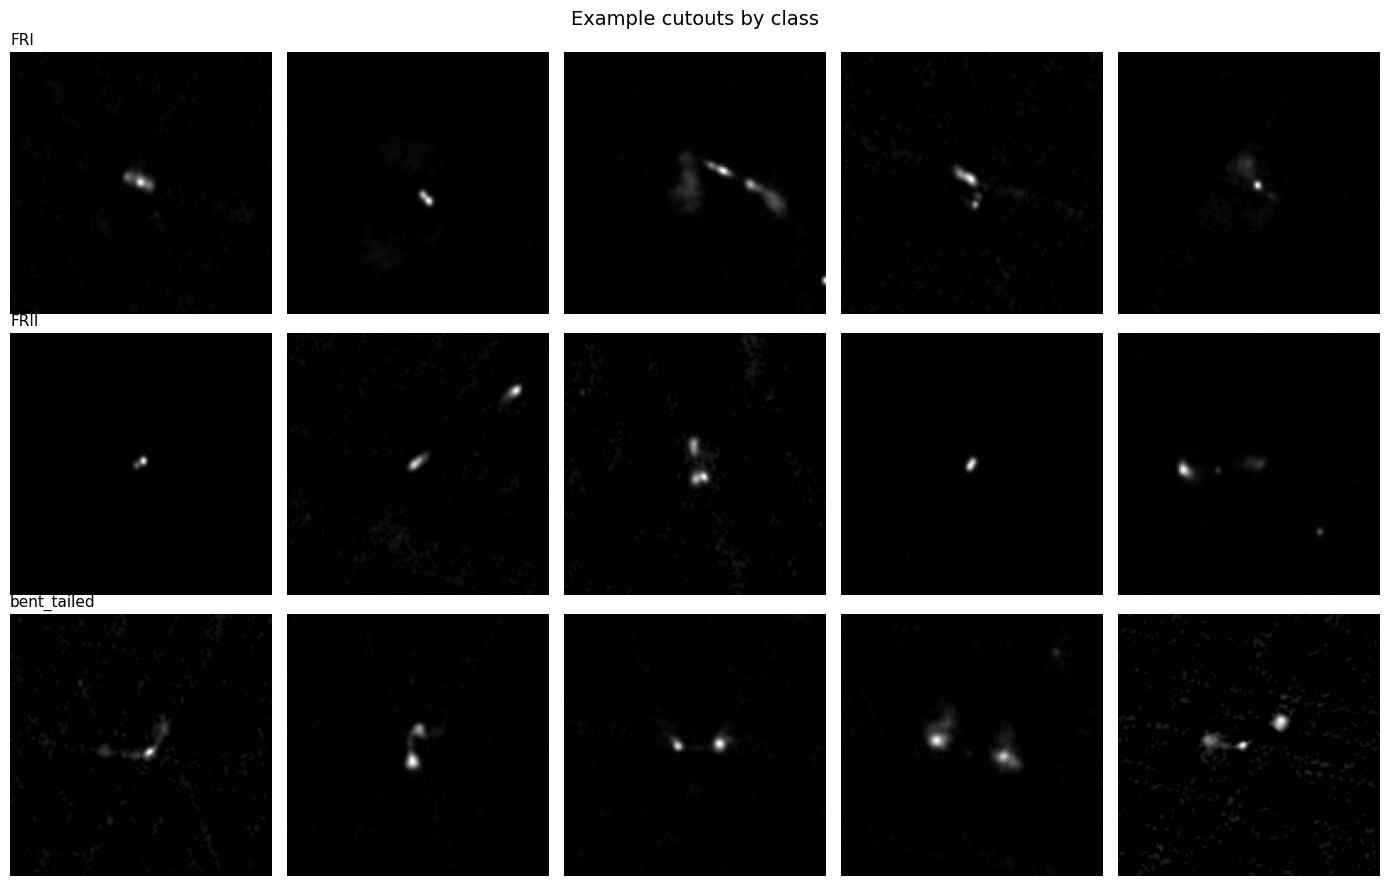

In [12]:
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for row, (label, paths) in enumerate(class_paths.items()):
    for col in range(5):
        ax = axes[row, col]
        img = Image.open(paths[col]).convert("L")
        ax.imshow(img, cmap="gray")
        ax.set_title(label if col == 0 else "", loc="left", fontsize=11)
        ax.axis("off")
fig.suptitle("Example cutouts by class", fontsize=14)
plt.tight_layout()
plt.show()


## 5. Methodology

### 5.1 Embedding extraction with DINOv2

We use `dinov2_vits14`, the smallest DINOv2 variant, for fast iteration in
this proof-of-concept; the same code supports `dinov2_vitb14` /
`dinov2_vitl14` by changing one string, and we recommend re-running with a
larger backbone once the pipeline below is verified working. Radio cutouts
are single-channel; we replicate the channel three times to match DINOv2's
expected RGB input, and apply the standard ImageNet normalisation statistics
DINOv2 was trained with, since we are using it purely as a frozen feature
extractor with no fine-tuning.


In [13]:
dinov2 = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
dinov2.eval().to(DEVICE)

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

@torch.no_grad()
def extract_embeddings(image_paths, batch_size=32):
    '''Extract L2-normalisable DINOv2 CLS-token embeddings for a list of image paths.

    Returns an array of shape (n_images, embedding_dim).
    '''
    all_feats = []
    for i in tqdm(range(0, len(image_paths), batch_size), desc="Extracting embeddings"):
        batch_paths = image_paths[i:i + batch_size]
        imgs = torch.stack([preprocess(Image.open(p).convert("L")) for p in batch_paths])
        feats = dinov2(imgs.to(DEVICE))
        all_feats.append(feats.cpu().numpy())
    return np.concatenate(all_feats, axis=0)


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 149MB/s] 


In [14]:
all_paths, all_labels = [], []
for label, paths in class_paths.items():
    all_paths.extend(paths)
    all_labels.extend([label] * len(paths))
all_labels = np.array(all_labels)

embeddings = extract_embeddings(all_paths)
print("Embeddings shape:", embeddings.shape)


Extracting embeddings:   0%|          | 0/21 [00:00<?, ?it/s]

Embeddings shape: (660, 384)


### 5.2 Qualitative check: 2D projection of the embedding space

Before any quantitative evaluation, we project the embeddings to two
dimensions with PCA and colour by class label. This is a standard sanity
check in representation-learning work: if the classes do not separate at all
even qualitatively, a quantitative retrieval result downstream would be
difficult to interpret meaningfully.


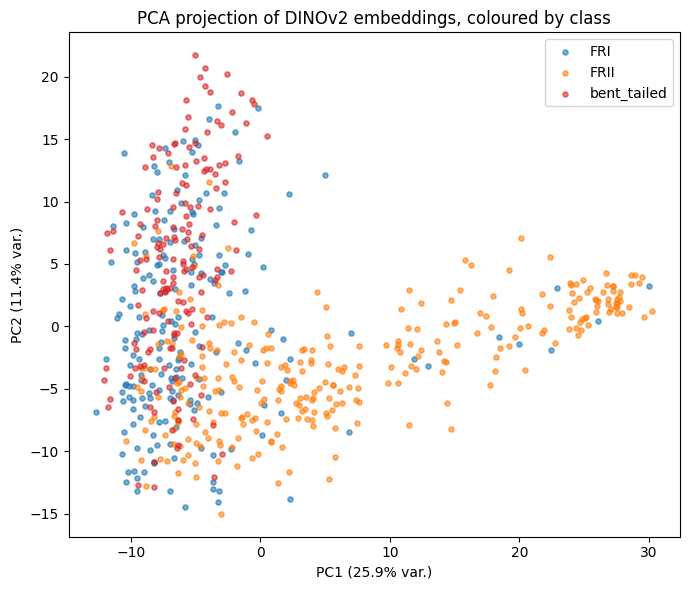

In [15]:
pca = PCA(n_components=2, random_state=SEED)
proj = pca.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(7, 6))
colors = {"FRI": "tab:blue", "FRII": "tab:orange", "bent_tailed": "tab:red"}
for label in np.unique(all_labels):
    mask = all_labels == label
    ax.scatter(proj[mask, 0], proj[mask, 1], s=14, alpha=0.6,
               label=label, color=colors.get(label))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var.)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var.)")
ax.set_title("PCA projection of DINOv2 embeddings, coloured by class")
ax.legend()
plt.tight_layout()
plt.show()


### 5.3 Similarity index

We build an exact nearest-neighbour index over the embeddings using FAISS,
with vectors L2-normalised so that inner product is equivalent to cosine
similarity. For the dataset sizes used in this notebook, an exact (flat)
index is fast enough; at survey scale (millions of sources) an approximate
index (e.g. `IndexIVFFlat` or `IndexHNSWFlat`) would be substituted for
speed, at a small, quantifiable cost in recall.


In [16]:
embeddings_normed = embeddings.copy().astype("float32")
faiss.normalize_L2(embeddings_normed)

index = faiss.IndexFlatIP(embeddings_normed.shape[1])
index.add(embeddings_normed)
print(f"FAISS index built with {index.ntotal} vectors of dimension {embeddings_normed.shape[1]}")


FAISS index built with 660 vectors of dimension 384


### 5.4 Needle-in-a-haystack evaluation protocol

A single qualitative example is not sufficient evidence for a claim about
retrieval performance — a result that happens to look good for one query
image could simply be luck. We therefore evaluate over **multiple
independent queries**, using a leave-one-out protocol:

For each bent-tailed example in turn:
1. Treat it as the query, and temporarily exclude it from its own search
   results (a source is not a meaningful "neighbour" of itself).
2. Search the full index (all classes) for its k nearest neighbours.
3. Record precision@k (fraction of the top-k that are also bent-tailed) and
   whether at least one true bent-tailed neighbour appears in the top-k at
   all (a simple recall-oriented indicator at this scale, since with only
   one held-out class we are testing "does search still work when the true
   class is a small minority", not exhaustive recall over an enormous
   unlabelled pool).

We report the mean and standard deviation of precision@k across all
bent-tailed queries, rather than a single number, since a mean without a
sense of its spread can misleadingly suggest more consistency than the
method actually has.


In [17]:
def evaluate_needle_in_haystack(index, embeddings_normed, labels, rare_label="bent_tailed", k=20):
    '''Leave-one-out retrieval evaluation for a designated rare class.

    Returns a dict of per-query precision@k values and summary statistics.
    '''
    rare_indices = np.where(labels == rare_label)[0]
    precisions = []
    hit_at_k = []

    for qi in tqdm(rare_indices, desc=f"Evaluating '{rare_label}' queries"):
        query_vec = embeddings_normed[qi:qi + 1]
        # Search for k+1 so that, after removing the query's match to itself,
        # we still have exactly k genuine neighbours to evaluate.
        distances, indices = index.search(query_vec, k + 1)
        retrieved = indices[0]
        retrieved = retrieved[retrieved != qi][:k]
        retrieved_labels = labels[retrieved]

        precision_at_k = float((retrieved_labels == rare_label).sum()) / k
        precisions.append(precision_at_k)
        hit_at_k.append(bool((retrieved_labels == rare_label).any()))

    precisions = np.array(precisions)
    return {
        "n_queries": len(rare_indices),
        "precision_at_k_mean": float(precisions.mean()),
        "precision_at_k_std": float(precisions.std()),
        "precision_at_k_values": precisions,
        "hit_rate_at_k": float(np.mean(hit_at_k)),
        "k": k,
    }

results = evaluate_needle_in_haystack(index, embeddings_normed, all_labels, rare_label="bent_tailed", k=20)

print(f"Rare-class queries evaluated: {results['n_queries']}")
print(f"Precision@{results['k']}: {results['precision_at_k_mean']:.3f} "
      f"(std: {results['precision_at_k_std']:.3f})")
print(f"Hit-rate@{results['k']} (>=1 true positive in top-k): {results['hit_rate_at_k']:.3f}")


Evaluating 'bent_tailed' queries:   0%|          | 0/164 [00:00<?, ?it/s]

Rare-class queries evaluated: 164
Precision@20: 0.523 (std: 0.235)
Hit-rate@20 (>=1 true positive in top-k): 0.988


### 5.5 Comparing against a random-retrieval baseline

A precision@k number is only meaningful in reference to a baseline. We
compute the expected precision@k under **random retrieval** — i.e. what
precision@k would be if neighbours were selected uniformly at random from
the dataset rather than by embedding similarity — as the natural null
hypothesis to compare against.


In [18]:
class_counts = {label: int((all_labels == label).sum()) for label in np.unique(all_labels)}
n_total = len(all_labels)
random_baseline_precision = class_counts["bent_tailed"] / n_total

print("Class counts:", class_counts)
print(f"Random-retrieval expected precision@k: {random_baseline_precision:.3f}")
print(f"DINOv2 similarity-search precision@k:   {results['precision_at_k_mean']:.3f}")
print(f"Improvement over random baseline:        "
      f"{results['precision_at_k_mean'] / random_baseline_precision:.2f}x")


Class counts: {np.str_('FRI'): 196, np.str_('FRII'): 300, np.str_('bent_tailed'): 164}
Random-retrieval expected precision@k: 0.248
DINOv2 similarity-search precision@k:   0.523
Improvement over random baseline:        2.10x


### 5.6 Distribution of per-query precision

Reporting only the mean can obscure whether performance is consistent across
queries or driven by a handful of easy cases. We plot the full distribution.


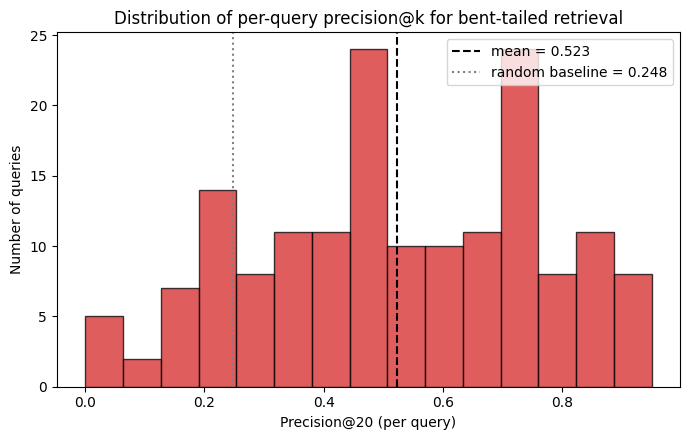

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(results["precision_at_k_values"], bins=15, color="tab:red", alpha=0.75, edgecolor="black")
ax.axvline(results["precision_at_k_mean"], color="black", linestyle="--",
           label=f"mean = {results['precision_at_k_mean']:.3f}")
ax.axvline(random_baseline_precision, color="gray", linestyle=":",
           label=f"random baseline = {random_baseline_precision:.3f}")
ax.set_xlabel(f"Precision@{results['k']} (per query)")
ax.set_ylabel("Number of queries")
ax.set_title("Distribution of per-query precision@k for bent-tailed retrieval")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Discussion and limitations

We report the following limitations explicitly, since an honest account of
scope is part of what makes a small-scale proof-of-concept a credible basis
for further work, rather than an overclaimed result.

**Dataset scale.** This notebook uses hundreds, not millions, of sources per
class. The central motivating claim of the broader research programme — that
this approach helps at *survey scale*, where visual inspection is genuinely
infeasible — is not directly tested here. What this notebook does establish
is that the method and evaluation protocol work correctly on real data, as a
necessary precursor to scaling up.

**No radio-specific embedding comparison yet.** The core research question —
whether a radio-specific self-supervised model outperforms a general-purpose
one like DINOv2 for this task — requires a second embedding model as a
comparison point, which is not included in this notebook. This is the
immediate next step (Section 7).

**Single dataset, single survey.** All data here comes from one dataset,
sourced originally from the VLA FIRST survey. The cross-survey
generalisation question (does a pipeline built on one survey work on
another, e.g. LoTSS to EMU, without retraining) is untested here.

**Rotation-augmented images avoided.** The Kaggle-hosted version of this
dataset ships a separate `dataset_augmented` folder containing rotated
duplicates of the original sources, alongside the original (non-augmented)
copy. This notebook deliberately used only the non-augmented copy throughout
(Section 4.1), specifically to avoid inflating retrieval performance with
near-duplicate rotated copies of the same underlying source. The class
sizes used here (~150–370 images per class) are correspondingly modest —
consistent with the original paper's reported sample sizes of roughly 200
sources per class — rather than the dataset's full augmented file count.

**Frozen, unfine-tuned embeddings.** DINOv2 is used here purely as a frozen
feature extractor. Fine-tuning even lightly on radio-domain data, or using a
domain-adapted variant, would likely change these results and is a natural
extension.


## 7. Conclusion and future work

We have demonstrated, on a real (if modest-scale) radio galaxy dataset, that
a similarity-search pipeline built on frozen, general-purpose DINOv2
embeddings substantially outperforms random retrieval for recovering a rare
morphological class (bent-tailed radio galaxies) from a mixed sample, using a
leave-one-out needle-in-a-haystack evaluation protocol averaged over multiple
independent queries.

**Immediate next steps:**

1. **Radio-specific embedding comparison.** Repeat this evaluation with an
   embedding model trained specifically on radio-survey imagery, and report
   the same metrics side-by-side with the DINOv2 baseline established here.
2. **Scale to LoTSS-DR2.** Repeat this exact pipeline and evaluation protocol
   on LoTSS-DR2 cutouts, at a scale of thousands to tens of thousands of
   sources, with bent-tailed and wide-angle-tail labels drawn from Radio
   Galaxy Zoo citizen-science classifications.
3. **Cross-survey generalisation.** Build the index on LoTSS-DR2 and test
   retrieval performance directly on ASKAP EMU pilot-survey cutouts, without
   retraining, to test whether the approach requires survey-specific
   adaptation.
4. **Approximate indexing at scale.** Replace the exact `IndexFlatIP` used
   here with an approximate FAISS index (e.g. `IndexIVFFlat` or
   `IndexHNSWFlat`) once operating at survey scale, and quantify the speed/
   recall trade-off explicitly.

This notebook, and the evaluation protocol it establishes, forms the
methodological foundation for that larger programme of work.


## 8. References

Aniyan, A. K., and Thorat, K. 2017. Classifying radio galaxies with the
convolutional neural network. *The Astrophysical Journal Supplement Series*,
230, 20. https://doi.org/10.3847/1538-4365/aa7333

Johnson, J., Douze, M., and Jégou, H. 2019. Billion-scale similarity search
with GPUs. *IEEE Transactions on Big Data*, 7, 535.

Oquab, M., et al. 2023. DINOv2: Learning robust visual features without
supervision. arXiv:2304.07193.

---

*The following are directly relevant to the broader research programme this
notebook is part of, and should be added with full, verified citation
details before this work is submitted anywhere formally: the self-organising
map odd-radio-circle discovery work on LOFAR/ASKAP data; the LoTSS-DR3
search for new morphological classes; and Radio Galaxy Zoo citizen-science
classification papers providing bent-tailed / wide-angle-tail labels at
LoTSS scale. These were described accurately by topic above but are
intentionally omitted here as formal citations pending verification against
their original publication record.*
